# SC452 Processes on Networks, Assignment 6
## Numerical part (Q2: SIS with periodic contact, Q3: SIR with one vaccination campaign)

Population is treated as homogeneously mixed, so there's no network anywhere here. I wrote my own fixed-step RK4 integrator instead of calling a library solver, mostly so I know exactly what step size is being used.

**Why RK4 with a fixed step:** both models are smooth and not stiff, and the fastest time scale is about 1 day (γ = 1 for Q2, and 1/(βs) is a few days for Q3). With dt = 0.01 day the step is about 100 times smaller than that, and RK4's global error goes like dt⁴, so it should be very accurate. I check this properly later by halving dt.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.precision", 5)

def rk4(f, y0, t0, t1, dt):
    # classic 4th order Runge-Kutta, y0 can be a scalar or a numpy array
    n = int(round((t1 - t0) / dt))
    t = t0 + dt * np.arange(n + 1)
    y = np.zeros((n + 1,) + np.shape(y0))
    y[0] = y0
    for k in range(n):
        tk, yk = t[k], y[k]
        k1 = f(tk, yk)
        k2 = f(tk + dt/2, yk + dt/2 * k1)
        k3 = f(tk + dt/2, yk + dt/2 * k2)
        k4 = f(tk + dt, yk + dt * k3)
        y[k+1] = yk + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
    return t, y

---
# Question 2: SIS model with periodic transmission

$$\frac{di}{dt} = \beta(t)\,i(1-i) - \gamma i,\qquad \beta(t) = 1.2 + A\sin(2\pi t/30),\quad \gamma = 1$$

The base case is A = 0.9. Period T = 30 days.

In [2]:
gamma = 1.0
T = 30.0
dt = 0.01

def beta_A(t, A=0.9):
    return 1.2 + A * np.sin(2*np.pi*t/T)

def sis_rhs(A):
    return lambda t, i: beta_A(t, A) * i * (1 - i) - gamma * i

ics = np.array([0.001, 0.2, 0.8])
# all three initial conditions are integrated together as a vector
t, I = rk4(sis_rhs(0.9), ics, 0, 600, dt)
print("steps:", len(t) - 1, " final values:", I[-1])

steps: 60000  final values: [0.00054726 0.00054726 0.00054726]


### (a) Solutions for the three initial conditions

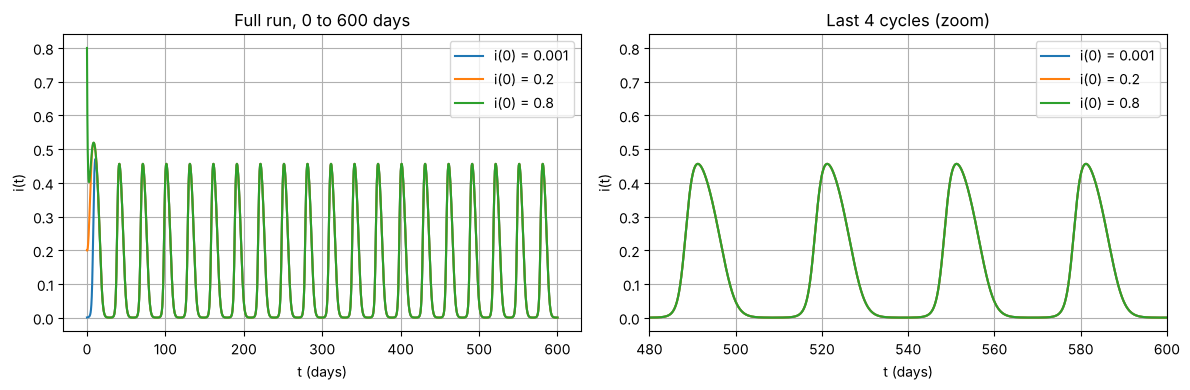

max |difference| between the curves over the last 30 days:
  0.001 vs 0.2 : 0.0
  0.2   vs 0.8 : 0.0


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, i0 in enumerate(ics):
    ax[0].plot(t, I[:, j], label=f"i(0) = {i0}")
    ax[1].plot(t, I[:, j], label=f"i(0) = {i0}")
ax[0].set_title("Full run, 0 to 600 days")
ax[1].set_xlim(480, 600); ax[1].set_title("Last 4 cycles (zoom)")
for a in ax:
    a.set_xlabel("t (days)"); a.set_ylabel("i(t)"); a.legend()
plt.tight_layout(); plt.show()

print("max |difference| between the curves over the last 30 days:")
last = t >= 570
print("  0.001 vs 0.2 :", np.abs(I[last, 0] - I[last, 1]).max())
print("  0.2   vs 0.8 :", np.abs(I[last, 1] - I[last, 2]).max())

All three runs end up on the same 30-day oscillation. The i(0)=0.8 run drops quickly, the 0.2 run is already close, and the 0.001 run needs a few cycles to grow out of the low region (net growth rate near i=0 is β̄ − γ = 0.2/day on average). In the zoom the three curves lie exactly on top of each other, so there is a single attracting periodic solution.

### (b) Cycle-to-cycle convergence

I sample the solution once per period, at t = 0, 30, 60, ... (same phase of β each time) and compare whole consecutive cycles.

**Criterion:** cycle n is "stabilised" when
$$\max_{0\le s<30} |i(30n+s) - i(30(n-1)+s)| < 10^{-6}$$
and this stays true for all later cycles.

 i(0)  converged cycle n  day  diff in last cycle
0.001                  3 90.0         7.77156e-16
0.200                  3 90.0         7.77156e-16
0.800                  3 90.0         7.77156e-16


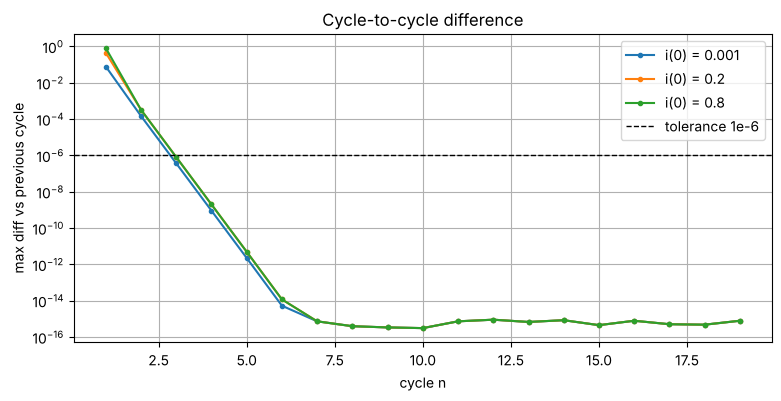


stroboscopic values i(30k) for the last few cycles:
       i0=0.001   i0=0.2   i0=0.8
510.0   0.00055  0.00055  0.00055
540.0   0.00055  0.00055  0.00055
570.0   0.00055  0.00055  0.00055
600.0   0.00055  0.00055  0.00055


In [4]:
spc = int(round(T / dt))           # steps per cycle
tol = 1e-6

def first_converged_cycle(y, tol=tol):
    ncyc = (len(y) - 1) // spc
    diffs = np.array([np.abs(y[n*spc:(n+1)*spc] - y[(n-1)*spc:n*spc]).max()
                      for n in range(1, ncyc)])
    ok = diffs < tol
    # first index after which everything stays below tol
    for k in range(len(ok)):
        if ok[k:].all():
            return k + 1, diffs
    return None, diffs

rows = []
for j, i0 in enumerate(ics):
    n, d = first_converged_cycle(I[:, j])
    rows.append([i0, n, n*T if n else None, d[-1]])
print(pd.DataFrame(rows, columns=["i(0)", "converged cycle n", "day", "diff in last cycle"]).to_string(index=False))

plt.figure()
for j, i0 in enumerate(ics):
    _, d = first_converged_cycle(I[:, j])
    plt.semilogy(np.arange(1, len(d)+1), d, "o-", ms=3, label=f"i(0) = {i0}")
plt.axhline(tol, color="k", ls="--", lw=1, label="tolerance 1e-6")
plt.xlabel("cycle n"); plt.ylabel("max diff vs previous cycle")
plt.title("Cycle-to-cycle difference"); plt.legend(); plt.show()

strobe = I[::spc]
print("\nstroboscopic values i(30k) for the last few cycles:")
print(pd.DataFrame(strobe[-4:], index=t[::spc][-4:], columns=[f"i0={x}" for x in ics]))

The differences fall off very fast. Every cycle pushes i down to about 5e-4 during the low-β phase, which squeezes the three solutions together, so all of them pass the 1e-6 test by cycle 3 (day 90). After that the differences reach round-off (they become exactly zero, so those points don't show on the log plot). Since this happens well before day 600 I didn't need to extend the run.

### (c) Properties of the converged cycle

min infected fraction  : 0.00049
max infected fraction  : 0.45639
time-averaged fraction : 0.12927
beta peaks at day 7.5 of each cycle, i peaks at day 11.23
delay between peaks    : 3.73 days


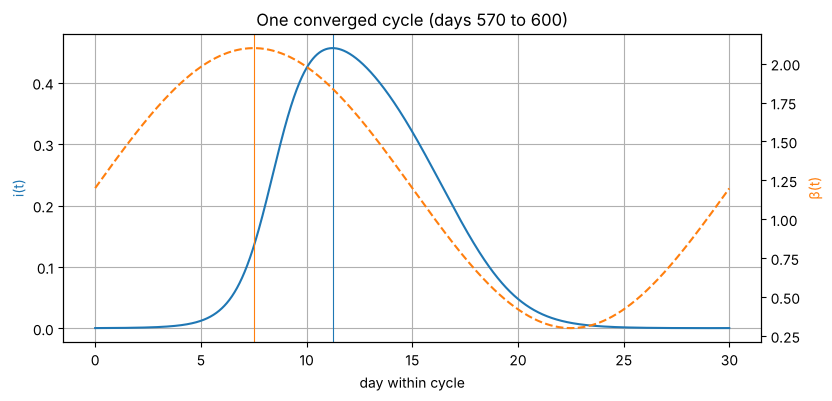

In [5]:
def cycle_stats(tt, yy, A):
    # tt, yy cover exactly one period [t0, t0+30) of a converged solution
    imin, imax = yy.min(), yy.max()
    imean = yy.mean()                    # uniform grid over one full period -> plain mean is fine
    if A == 0:
        return imin, imax, imean, np.nan
    t_peak_i = tt[yy.argmax()] % T
    t_peak_b = 7.5                       # sin(2*pi*t/30) = 1 at t = 7.5 (mod 30)
    delay = (t_peak_i - t_peak_b) % T
    return imin, imax, imean, delay

sel = (t >= 570) & (t < 600)
tc, yc = t[sel], I[sel, 1]
imin, imax, imean, delay = cycle_stats(tc, yc, 0.9)
print(f"min infected fraction  : {imin:.5f}")
print(f"max infected fraction  : {imax:.5f}")
print(f"time-averaged fraction : {imean:.5f}")
print(f"beta peaks at day 7.5 of each cycle, i peaks at day {tc[yc.argmax()] % T:.2f}")
print(f"delay between peaks    : {delay:.2f} days")

fig, ax1 = plt.subplots()
ax1.plot(tc - 570, yc, "C0", label="i(t)")
ax1.set_xlabel("day within cycle"); ax1.set_ylabel("i(t)", color="C0")
ax2 = ax1.twinx()
ax2.plot(tc - 570, beta_A(tc), "C1--", label="β(t)")
ax2.set_ylabel("β(t)", color="C1"); ax2.grid(False)
ax1.axvline(7.5, color="C1", lw=0.8); ax1.axvline(tc[yc.argmax()] - 570, color="C0", lw=0.8)
ax1.set_title("One converged cycle (days 570 to 600)")
plt.show()

The infection peak comes a few days after the transmission peak. That makes sense: i keeps increasing as long as β(t)(1−i) > γ, so it carries on growing even after β has started to drop, and only turns around once β(1−i) falls below 1. The minimum is very small (about 5e-4), so between waves the infection almost dies out.

### (d) Constant transmission β̄ = 1.2

With constant β the endemic equilibrium is i* = 1 − γ/β̄ = 1 − 1/1.2 = 1/6 ≈ 0.1667.

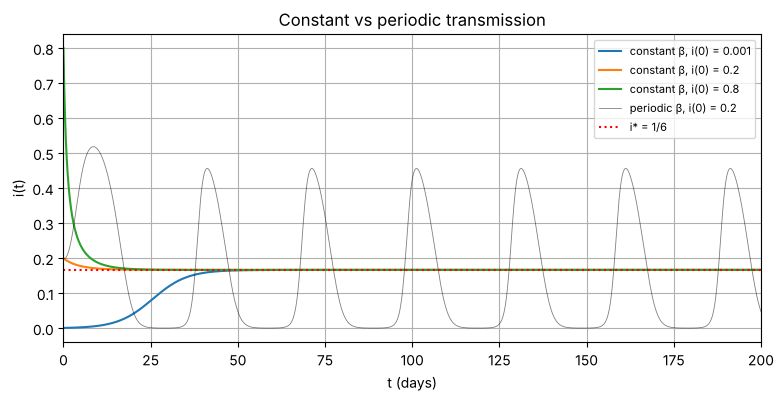

final values with constant β: [0.16666667 0.16666667 0.16666667]
                        constant β (long-run)  periodic β (A=0.9)  \
mean infected fraction                0.16667             0.12927   
max infected fraction                 0.16667             0.45639   

                        relative difference %  
mean infected fraction               28.93018  
max infected fraction               -63.48113  


In [6]:
t0_, I0_ = rk4(sis_rhs(0.0), ics, 0, 600, dt)
plt.figure()
for j, i0 in enumerate(ics):
    plt.plot(t0_, I0_[:, j], label=f"constant β, i(0) = {i0}")
plt.plot(t, I[:, 1], "k", lw=0.6, alpha=0.5, label="periodic β, i(0) = 0.2")
plt.axhline(1 - 1/1.2, color="r", ls=":", label="i* = 1/6")
plt.xlim(0, 200); plt.xlabel("t (days)"); plt.ylabel("i(t)"); plt.legend(fontsize=8)
plt.title("Constant vs periodic transmission"); plt.show()

comp = pd.DataFrame({
    "constant β (long-run)": [I0_[-1, 1], I0_[-1, 1]],
    "periodic β (A=0.9)": [imean, imax]},
    index=["mean infected fraction", "max infected fraction"])
comp["relative difference %"] = 100 * (comp.iloc[:, 0] - comp.iloc[:, 1]) / comp.iloc[:, 1]
print("final values with constant β:", I0_[-1])
print(comp)

The averaged model settles at 0.1667 for every initial condition. Compared with the periodic model it **overestimates the mean** (0.167 vs about 0.129, roughly 29% higher) but **badly underestimates the peak** (0.167 vs about 0.456, close to 3 times smaller). So for planning things like peak capacity the averaged model would be misleading.

### (e) Effect of the amplitude A

A goes from 0 to 1.1 in steps of 0.05. All A values are integrated together as one vector. I run for 900 days to make sure everything has converged (checked below with the same 1e-6 criterion), then take the last full cycle.

**A = 0:** β is constant, so i just sits at 1/6 and there is no peak at all. Peak delay is undefined, so I store it as NaN rather than putting in a meaningless number. (Any tiny A > 0 gives a well defined delay, and the A → 0 limit of the delay can be read off from the trend.)

In [7]:
A_vals = np.round(np.arange(0, 1.1001, 0.05), 2)

def sweep(A_vals, dt, t_end=900):
    f = lambda tt, i: beta_A(tt, A_vals) * i * (1 - i) - gamma * i
    tt, Y = rk4(f, np.full(len(A_vals), 0.2), 0, t_end, dt)
    spc_ = int(round(T / dt))
    sel = slice(len(tt) - 1 - spc_, len(tt) - 1)          # last full period [t_end-30, t_end)
    prev = slice(len(tt) - 1 - 2*spc_, len(tt) - 1 - spc_)
    out = []
    for k, A in enumerate(A_vals):
        s = cycle_stats(tt[sel], Y[sel, k], A)
        conv = np.abs(Y[sel, k] - Y[prev, k]).max()
        out.append([A, *s, conv])
    return pd.DataFrame(out, columns=["A", "min i", "max i", "mean i", "peak delay (days)", "last cycle diff"])

tab = sweep(A_vals, dt)
print(tab.to_string(index=False))

   A   min i   max i  mean i  peak delay (days)  last cycle diff
0.00 0.16667 0.16667 0.16667                NaN      0.00000e+00
0.05 0.14293 0.19072 0.16632               3.71      1.38778e-16
0.10 0.12004 0.21460 0.16532               3.58      1.94289e-16
0.15 0.09855 0.23792 0.16371               3.47      2.77556e-16
0.20 0.07899 0.26037 0.16160               3.38      2.77556e-16
0.25 0.06175 0.28173 0.15911               3.31      3.33067e-16
0.30 0.04709 0.30187 0.15638               3.27      3.33067e-16
0.35 0.03506 0.32070 0.15353               3.25      4.16334e-16
0.40 0.02551 0.33822 0.15066               3.25      8.60423e-16
0.45 0.01819 0.35445 0.14786               3.26      7.21645e-16
0.50 0.01273 0.36946 0.14519               3.29      8.88178e-16
0.55 0.00877 0.38333 0.14267               3.33      4.99600e-16
0.60 0.00596 0.39616 0.14032               3.38      6.66134e-16
0.65 0.00401 0.40804 0.13813               3.43      7.21645e-16
0.70 0.00267 0.41907 0.13

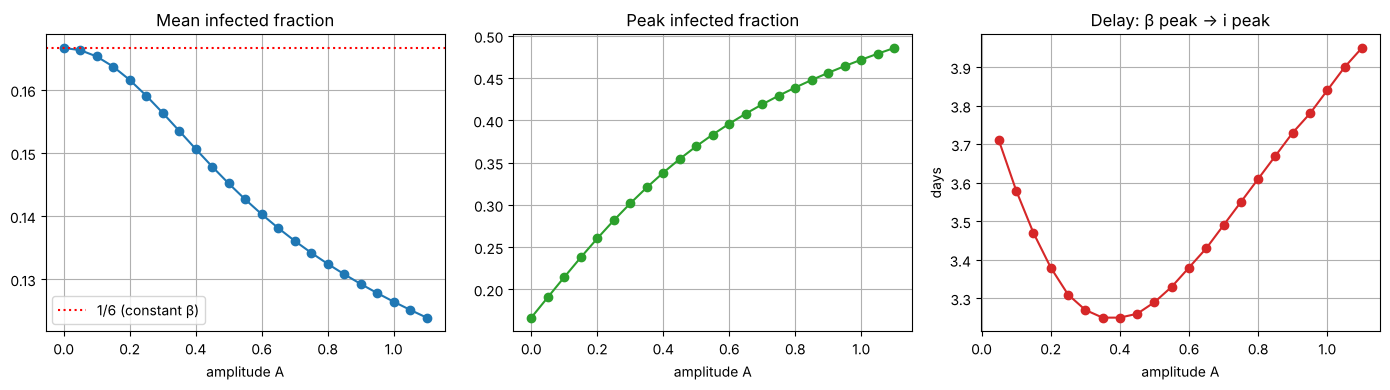

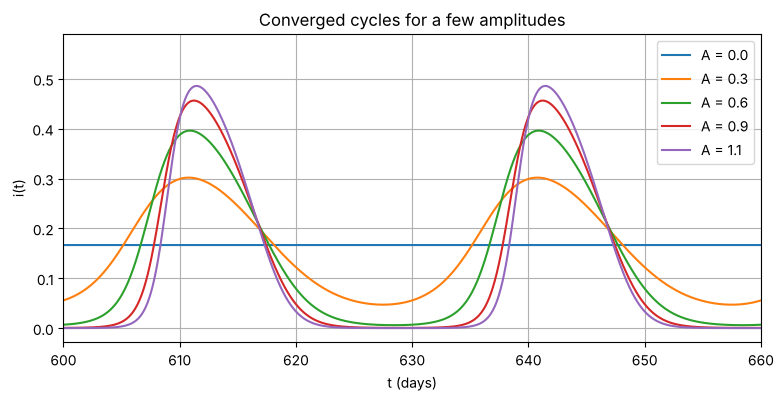

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(tab["A"], tab["mean i"], "o-"); ax[0].axhline(1/6, color="r", ls=":", label="1/6 (constant β)")
ax[0].set_title("Mean infected fraction"); ax[0].legend()
ax[1].plot(tab["A"], tab["max i"], "o-", color="C2"); ax[1].set_title("Peak infected fraction")
ax[2].plot(tab["A"], tab["peak delay (days)"], "o-", color="C3"); ax[2].set_title("Delay: β peak → i peak")
ax[2].set_ylabel("days")
for a in ax: a.set_xlabel("amplitude A")
plt.tight_layout(); plt.show()

# a few cycles for different A to see the shape
tt, Y = rk4(lambda s, i: beta_A(s, np.array([0.0, 0.3, 0.6, 0.9, 1.1])) * i*(1-i) - gamma*i,
            np.full(5, 0.2), 0, 660, dt)
plt.figure()
for k, A in enumerate([0.0, 0.3, 0.6, 0.9, 1.1]):
    plt.plot(tt, Y[:, k], label=f"A = {A}")
plt.xlim(600, 660); plt.xlabel("t (days)"); plt.ylabel("i(t)"); plt.legend()
plt.title("Converged cycles for a few amplitudes"); plt.show()

Observations:
- **Mean** goes down as A increases (0.1667 at A=0 down to about 0.124 at A=1.1). The mean is not the same as the constant-β answer, because the right-hand side is nonlinear in i. During the low-β part of the cycle the infection crashes almost to zero and wastes a lot of the "high β" time regrowing from a small value.
- **Peak** goes up a lot with A, from 0.167 to about 0.49. The swing (max − min) gets bigger and bigger.
- **Peak delay** stays around 3.2 to 4 days. It has a shallow minimum around A ≈ 0.35 to 0.4 and grows slowly for large A. At A = 0 it's undefined as explained above.
- The last column shows every run had converged to better than 1e-6 by day 900.

### (f) Accuracy check and conclusion

I repeat the A = 0.9 calculation with dt = 0.04, 0.02, 0.01 and 0.005. If RK4 is working properly the differences should shrink by about 16 each time dt is halved.

In [9]:
rows = []
for h in [0.04, 0.02, 0.01, 0.005]:
    tt, Y = rk4(sis_rhs(0.9), 0.2, 0, 600, h)
    n = int(round(T / h))
    rows.append([h, *cycle_stats(tt[-1-n:-1], Y[-1-n:-1], 0.9)])
acc = pd.DataFrame(rows, columns=["dt", "min i", "max i", "mean i", "delay"])
ref = acc.iloc[-1]
acc["|max - ref|"] = (acc["max i"] - ref["max i"]).abs()
acc["|mean - ref|"] = (acc["mean i"] - ref["mean i"]).abs()
print(acc.to_string(index=False))

# also re-run the amplitude sweep with half the step
tab2 = sweep(A_vals, dt/2)
print("\nlargest change in the amplitude table when dt is halved:")
print("  mean i :", (tab["mean i"] - tab2["mean i"]).abs().max())
print("  max i  :", (tab["max i"] - tab2["max i"]).abs().max())
print("  delay  :", (tab["peak delay (days)"] - tab2["peak delay (days)"]).abs().max(), "days (grid resolution of the delay is dt)")

   dt   min i   max i  mean i  delay  |max - ref|  |mean - ref|
0.040 0.00049 0.45638 0.12927  3.740  3.01988e-06   8.58980e-10
0.020 0.00049 0.45638 0.12927  3.720  6.37428e-07   5.44640e-11
0.010 0.00049 0.45639 0.12927  3.730  1.86029e-07   3.23186e-12
0.005 0.00049 0.45639 0.12927  3.725  0.00000e+00   0.00000e+00



largest change in the amplitude table when dt is halved:
  mean i : 8.569409071235157e-12
  max i  : 3.485174130402058e-07
  delay  : 0.005000000000109139 days (grid resolution of the delay is dt)


Halving dt changes the mean by about 1e-11 and the max by under 1e-6 (the max is limited by how finely the grid catches the top of the peak, not by RK4 error), so dt = 0.01 is more than enough. The delay is only resolved to the grid spacing (0.01 day), which is fine for this purpose.

**Is the average transmission enough?** No, not in this model. Replacing β(t) by β̄ gets the mean wrong by almost 30% and misses the peak by nearly a factor of 3, and it can't say anything about the timing of waves. The infection responds nonlinearly to β, so the timing and size of the fluctuations matter, not just the average.

---
# Question 3: SIR model with one vaccination campaign

$$s' = -0.6\,si,\quad i' = 0.6\,si - 0.2\,i,\quad r' = 0.2\,i,\qquad s(0)=0.998,\; i(0)=0.002$$

R₀ = 0.6/0.2 = 3. Population N = 10,000, so the cap of 500 infected means i ≤ 0.05.

I split r into two parts: **v** (vaccinated) and **rec** (recovered after infection). The ODE is the same, the vaccinated just never move.

**Stopping rule:** the outbreak is taken to be over once i(t) < 1e-7 (that's 0.001 people, so well below one person) and di/dt < 0. As a safety cap I stop at 1000 days anyway.

In [10]:
b, g = 0.6, 0.2
N = 10_000
cap = 500 / N           # = 0.05
dt3 = 0.01

def sir_rhs(t, y):
    s, i, rec, v = y[0], y[1], y[2], y[3]
    inf = b * s * i
    return np.array([-inf, inf - g*i, g*i, 0*v])

def simulate(tau=None, p=0.0, dt=dt3, s0=0.998, i0=0.002, i_stop=1e-7, t_max=1000):
    # returns t, y with columns s, i, rec, v
    y = np.array([s0, i0, 0.0, 0.0])
    ts, ys = [0.0], [y.copy()]
    if tau is not None and tau == 0:
        y = np.array([(1-p)*y[0], y[1], y[2], y[3] + p*y[0]])
        ts.append(0.0); ys.append(y.copy())
    tk, done_vax = 0.0, (tau is None or tau == 0)
    n_tau = None if tau is None else int(round(tau / dt))
    k = 0
    while tk < t_max:
        k1 = sir_rhs(tk, y); k2 = sir_rhs(tk, y + dt/2*k1)
        k3 = sir_rhs(tk, y + dt/2*k2); k4 = sir_rhs(tk, y + dt*k3)
        y = y + dt/6*(k1 + 2*k2 + 2*k3 + k4)
        k += 1; tk = k * dt
        ts.append(tk); ys.append(y.copy())
        if not done_vax and k == n_tau:
            y = np.array([(1-p)*y[0], y[1], y[2], y[3] + p*y[0]])   # instant campaign
            ts.append(tk); ys.append(y.copy())
            done_vax = True
        if done_vax and y[1] < i_stop and b*y[0]*y[1] - g*y[1] < 0:
            break
    return np.array(ts), np.array(ys)

### (a) No vaccination

peak infected fraction : 0.30113  ->  3011 residents
time of peak           : 17.43 days
final s                : 0.05938
eventual fraction infected (1 - s_inf, includes initial 20): 0.94062  ->  9406 residents
simulation stopped at t = 112.9 days (i = 1.0e-07)
final-size relation residual: 2.99729700170559e-07
peak check from s+i - ln(s)/R0 = const : 0.3011299046675211 vs 0.30112990018884833


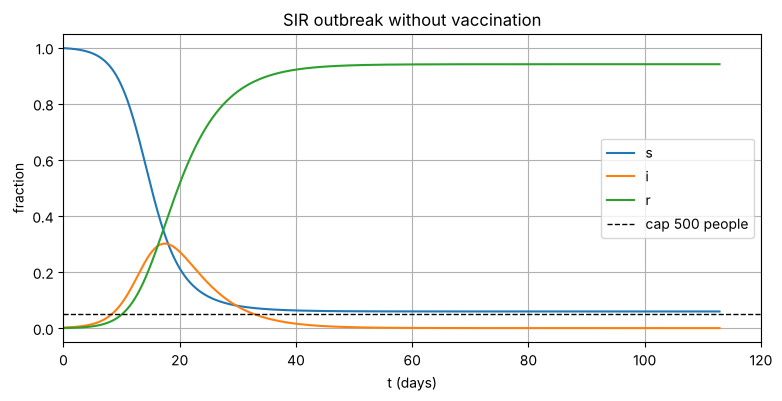

In [11]:
t_nv, y_nv = simulate()
s, i, rec = y_nv[:, 0], y_nv[:, 1], y_nv[:, 2]
k = i.argmax()
print(f"peak infected fraction : {i[k]:.5f}  ->  {i[k]*N:.0f} residents")
print(f"time of peak           : {t_nv[k]:.2f} days")
print(f"final s                : {s[-1]:.5f}")
print(f"eventual fraction infected (1 - s_inf, includes initial 20): {1 - s[-1]:.5f}  ->  {(1-s[-1])*N:.0f} residents")
print(f"simulation stopped at t = {t_nv[-1]:.1f} days (i = {i[-1]:.1e})")

# check: final size relation  ln(s_inf/s0) = R0 (s_inf - 1)  since r0=0, s0+i0=1
R0 = b/g
print("final-size relation residual:", np.log(s[-1]/0.998) - R0*(s[-1] - 1))
print("peak check from s+i - ln(s)/R0 = const :", 0.998 + 0.002 - np.log(0.998)/R0 - (1/R0 + (-np.log(1/R0))/R0), "vs", i[k])

plt.figure()
plt.plot(t_nv, s, label="s"); plt.plot(t_nv, i, label="i"); plt.plot(t_nv, rec, label="r")
plt.axhline(cap, color="k", ls="--", lw=1, label="cap 500 people")
plt.xlim(0, 120); plt.xlabel("t (days)"); plt.ylabel("fraction"); plt.legend()
plt.title("SIR outbreak without vaccination"); plt.show()

Without vaccination about 3011 people are infected at the same time at the peak (day 17.4), six times the limit, and about 94% of the town gets infected in the end. The outbreak is "over" by my criterion at about day 113. Both numbers agree with the standard SIR relations: the peak matches the invariant s + i − ln(s)/R₀ to about 1e-8, and the final-size equation is satisfied to about 3e-7 (which is roughly what you'd expect from stopping at i = 1e-7 instead of exactly 0).

### (b) Minimum p for each campaign day τ

For a given τ:
1. Before the campaign nothing changes, so if max i on [0, τ] is already above 0.05 then τ is **infeasible** whatever p is.
2. After the campaign the peak of i can only go down as p increases (fewer susceptibles), so the condition is monotone in p and I can use **bisection** on p ∈ [0, 0.9]. If even p = 0.9 isn't enough, τ is infeasible.

To make this fast I use the fact that the SIR system is autonomous: after the campaign the trajectory depends only on (s(τ⁺), i(τ⁺)), not on τ itself. So I store the no-vaccination trajectory, read off the state at each τ, and then integrate all τ values at once as vectors.

In [12]:
def post_peak(s_start, i_start, dt=dt3, T_run=400):
    # vectorised RK4 for many starting states at once, returns max of i over the run
    s_, i_ = np.array(s_start, float), np.array(i_start, float)
    mx = i_.copy()
    f = lambda s, i: (-b*s*i, b*s*i - g*i)
    for _ in range(int(round(T_run/dt))):
        a1, c1 = f(s_, i_)
        a2, c2 = f(s_ + dt/2*a1, i_ + dt/2*c1)
        a3, c3 = f(s_ + dt/2*a2, i_ + dt/2*c2)
        a4, c4 = f(s_ + dt*a3, i_ + dt*c3)
        s_ = s_ + dt/6*(a1 + 2*a2 + 2*a3 + a4)
        i_ = i_ + dt/6*(c1 + 2*c2 + 2*c3 + c4)
        mx = np.maximum(mx, i_)
        if np.all(i_ < 1e-7): break
    return mx

def min_p_table(taus, dt=dt3, n_bisect=40):
    tb, yb = simulate(dt=dt, t_max=31)           # no-vaccine path up to day 31
    idx = np.round(np.asarray(taus) / dt).astype(int)
    s_tau, i_tau = yb[idx, 0], yb[idx, 1]
    pre_max = np.array([yb[:j+1, 1].max() for j in idx])

    feasible = (pre_max <= cap) & (post_peak((1-0.9)*s_tau, i_tau, dt) <= cap)
    lo, hi = np.zeros(len(taus)), np.full(len(taus), 0.9)
    for _ in range(n_bisect):
        mid = (lo + hi) / 2
        ok = post_peak((1-mid)*s_tau, i_tau, dt) <= cap
        hi = np.where(ok, mid, hi)
        lo = np.where(ok, lo, mid)
    p_min = np.where(feasible, hi, np.nan)
    D = N * p_min * s_tau
    return pd.DataFrame({"tau": taus, "s(tau-)": s_tau, "i(tau)*N": i_tau*N,
                         "max i before tau *N": pre_max*N, "feasible": feasible,
                         "p_min": p_min, "doses D": D})

taus = np.arange(0, 30.01, 0.5)
res = min_p_table(taus)
print(res.to_string(index=False))

 tau  s(tau-)   i(tau)*N  max i before tau *N  feasible   p_min    doses D
 0.0  0.99800   20.00000             20.00000      True 0.45336 4524.48741
 0.5  0.99734   24.41106             24.41106      True 0.45413 4529.22123
 1.0  0.99653   29.78844             29.78844      True 0.45508 4535.03989
 1.5  0.99554   36.34063             36.34063      True 0.45625 4542.20224
 2.0  0.99435   44.31954             44.31954      True 0.45769 4551.03397
 2.5  0.99288   54.02880             54.02880      True 0.45946 4561.94821
 3.0  0.99111   65.83322             65.83322      True 0.46165 4575.47384
 3.5  0.98894   80.16946             80.16946      True 0.46436 4592.29533
 4.0  0.98632   97.55781             97.55781      True 0.46773 4613.31130
 4.5  0.98314  118.61452            118.61452      True 0.47193 4639.72476
 5.0  0.97928  144.06437            144.06437      True 0.47721 4673.18527
 5.5  0.97462  174.75206            174.75206      True 0.48388 4716.03119
 6.0  0.96901  211.65109 

feasible campaign days: tau from 0.0 to 8.0
infeasible: every tau >= 8.5


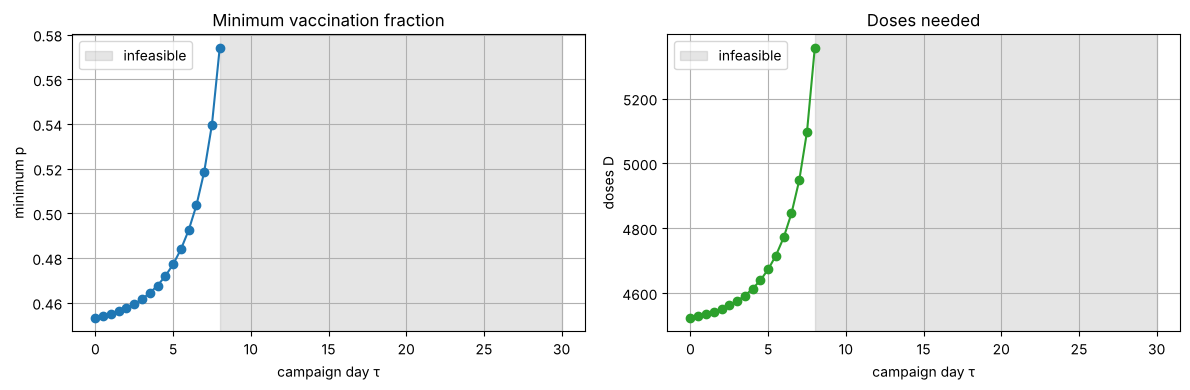

In [13]:
feas = res[res.feasible]
print("feasible campaign days: tau from", feas.tau.min(), "to", feas.tau.max())
print("infeasible: every tau >=", res[~res.feasible].tau.min())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(feas.tau, feas.p_min, "o-"); ax[0].set_ylabel("minimum p"); ax[0].set_title("Minimum vaccination fraction")
ax[1].plot(feas.tau, feas["doses D"], "o-", color="C2"); ax[1].set_ylabel("doses D"); ax[1].set_title("Doses needed")
for a in ax:
    a.set_xlabel("campaign day τ"); a.axvspan(feas.tau.max(), 30, color="grey", alpha=0.2, label="infeasible")
    a.legend()
plt.tight_layout(); plt.show()

Campaigns stop being feasible after about day 8.33. Without vaccination the number infected passes 500 at around day 8.33, so for any later τ the cap is already broken **before** the campaign happens, and vaccinating susceptibles can't undo that. So τ = 15 and everything after day 8.5 on this grid is impossible. (p = 0.9 is enough for every τ up to the edge, so the upper limit on p never ends up being the problem.)

Close to the edge the required p shoots up, because i(τ) is already near 0.05 and you need to push s below about 1/3 = γ/β so that i stops growing almost immediately.

### (c) Minimum number of doses

Looking at the table, D goes **up** with τ the whole way, so the coarse optimum is τ = 0. My first guess was that waiting might save doses (fewer susceptibles left), but s(τ) barely drops in the first week while i(τ) grows fast, and a bigger i(τ) means s has to be pushed further down to stay under the cap. The second effect wins.

To be sure it isn't a coarse-grid artifact I refine on [0, 1] with step 0.01 day (that's equal to dt, campaigns have to be on a grid point).

In [14]:
best_coarse = feas.loc[feas["doses D"].idxmin()]
print("coarse best:", dict(best_coarse[["tau", "p_min", "doses D"]]))

lo_t = max(0.0, best_coarse.tau - 1.0)
taus_fine = np.round(np.arange(lo_t, best_coarse.tau + 1.0 + 1e-9, 0.01), 2)
fine = min_p_table(taus_fine)
ff = fine[fine.feasible]
best = ff.loc[ff["doses D"].idxmin()]
print("D is increasing along the fine grid:", bool(np.all(np.diff(ff["doses D"]) > 0)))
print(f"optimal tau  = {best.tau:.2f} days   (resolution 0.01 day)")
print(f"optimal p    = {best.p_min:.6f}       (bisection error < {0.9/2**40:.1e})")
print(f"s(tau-)      = {best['s(tau-)']:.5f}")
print(f"doses D      = {best['doses D']:.1f}")
print(ff.head(6).to_string(index=False))

coarse best: {'tau': np.float64(0.0), 'p_min': np.float64(0.4533554514257048), 'doses D': np.float64(4524.487405228534)}


D is increasing along the fine grid: True
optimal tau  = 0.00 days   (resolution 0.01 day)
optimal p    = 0.453355       (bisection error < 8.2e-13)
s(tau-)      = 0.99800
doses D      = 4524.5
 tau  s(tau-)  i(tau)*N  max i before tau *N  feasible   p_min    doses D
0.00  0.99800  20.00000             20.00000      True 0.45336 4524.48741
0.01  0.99799  20.07992             20.07992      True 0.45337 4524.57286
0.02  0.99798  20.16015             20.16015      True 0.45338 4524.65864
0.03  0.99796  20.24071             20.24071      True 0.45340 4524.74477
0.04  0.99795  20.32159             20.32159      True 0.45341 4524.83125
0.05  0.99794  20.40278             20.40278      True 0.45343 4524.91816


So the optimum is to vaccinate straight away: τ* = 0 with p* ≈ 0.4534, about 4524 doses. The resolution is 0.01 day in τ and better than 1e-12 in p (40 bisection steps), so D is accurate to well under one dose as far as the search goes. Near τ = 0 the curve is quite flat (waiting half a day only costs about 5 extra doses), but it is still increasing.

### (d) Compare optimal campaign with τ = 0 and τ = 15

Since the optimum came out at τ = 0, the "optimal" and "day 0" rows are the same campaign. I add τ = 8 (the last feasible day on the half-day grid) to show what waiting costs.

In [15]:
def describe(tau, p, s_minus):
    tt, yy = simulate(tau=tau, p=p)
    return {"tau": tau, "p": p, "doses": N*p*s_minus, "peak infected (people)": yy[:, 1].max()*N,
            "peak time": tt[yy[:, 1].argmax()]}

row0 = res[res.tau == 0].iloc[0]
row8 = res[res.tau == 8].iloc[0]
cases = [describe(best.tau, best.p_min, best["s(tau-)"]), describe(0.0, row0.p_min, row0["s(tau-)"]),
         describe(8.0, row8.p_min, row8["s(tau-)"])]
df_d = pd.DataFrame(cases, index=["optimal", "day 0", "day 8 (late, for comparison)"])
print(df_d)

r15 = res[res.tau == 15].iloc[0]
print(f"\nday 15: max infected before the campaign = {r15['max i before tau *N']:.0f} people  (> 500)  -> infeasible")
print("even with p = 0.9 on day 15, peak infected =", describe(15.0, 0.9, r15["s(tau-)"])["peak infected (people)"].round(0), "people")

                              tau        p       doses  \
optimal                       0.0  0.45336  4524.48741   
day 0                         0.0  0.45336  4524.48741   
day 8 (late, for comparison)  8.0  0.57404  5355.96939   

                              peak infected (people)  peak time  
optimal                                        500.0      37.04  
day 0                                          500.0      37.04  
day 8 (late, for comparison)                   500.0      14.09  

day 15: max infected before the campaign = 2667 people  (> 500)  -> infeasible
even with p = 0.9 on day 15, peak infected = 2667.0 people


- **Optimal = day 0:** vaccinate about 45% of susceptibles, roughly 4524 doses. The peak sits right at 500 people (the minimum p makes the constraint tight), and it comes much later than in the unvaccinated outbreak.
- **Day 8:** still feasible, but needs p ≈ 0.574 and about 5356 doses, so roughly 830 more than going on day 0. Its peak comes at day ~14 instead of ~37.
- **Day 15:** impossible. By day 15 there are already ~2,670 people infected at once, and the cap was broken around day 8. Vaccination only protects susceptibles, it does nothing for those already infected, so no p can bring the earlier peak back under 500.

### (e) Eventual fraction infected (vaccinated tracked separately)

Eventual infected = 1 − s(∞) − v. This counts the initial 20 infected people too. Note that r(∞) = rec + v is **not** the number infected, since v includes people who never got sick.

In [16]:
rows = []
for _, rr in feas.iterrows():
    tt, yy = simulate(tau=rr.tau, p=rr.p_min)
    s_inf, i_end, rec_inf, v = yy[-1]
    rows.append([rr.tau, rr.p_min, rr["doses D"], v, rec_inf + i_end, 1 - s_inf - v, rec_inf + v])
df_e = pd.DataFrame(rows, columns=["tau", "p", "doses", "vaccinated v", "infected (rec+i)",
                                   "1 - s_inf - v", "total removed r"])
print(df_e.to_string(index=False))

 tau       p      doses  vaccinated v  infected (rec+i)  1 - s_inf - v  total removed r
 0.0 0.45336 4524.48741       0.45245           0.36509        0.36509          0.81754
 0.5 0.45413 4529.22123       0.45292           0.36462        0.36462          0.81754
 1.0 0.45508 4535.03989       0.45350           0.36404        0.36404          0.81754
 1.5 0.45625 4542.20224       0.45422           0.36332        0.36332          0.81754
 2.0 0.45769 4551.03397       0.45510           0.36244        0.36244          0.81754
 2.5 0.45946 4561.94821       0.45619           0.36135        0.36135          0.81754
 3.0 0.46165 4575.47384       0.45755           0.36000        0.36000          0.81754
 3.5 0.46436 4592.29533       0.45923           0.35831        0.35831          0.81754
 4.0 0.46773 4613.31130       0.46133           0.35621        0.35621          0.81754
 4.5 0.47193 4639.72476       0.46397           0.35357        0.35357          0.81754
 5.0 0.47721 4673.18527       0.

The two "infected" columns agree, so the bookkeeping is right. Interesting points:
- The total removed r(∞) = rec + v is **exactly the same (0.8175)** for every feasible campaign. That's not a coincidence: with minimum p the peak is always exactly 0.05, and after the campaign s + i − ln(s)/R₀ is conserved, so the same peak value forces the same final s. So r(∞) clearly can't be used as "fraction infected", it mixes in 45 to 54% vaccinated people.
- The infected fraction goes **down** for later campaigns, from 36.5% (τ = 0) to 28.2% (τ = 8). So there's a trade-off: day 0 is cheapest in doses, but a later campaign ends with fewer total infections (more doses replace infections one-for-one).

### (f) Optimal trajectory, checks and stability

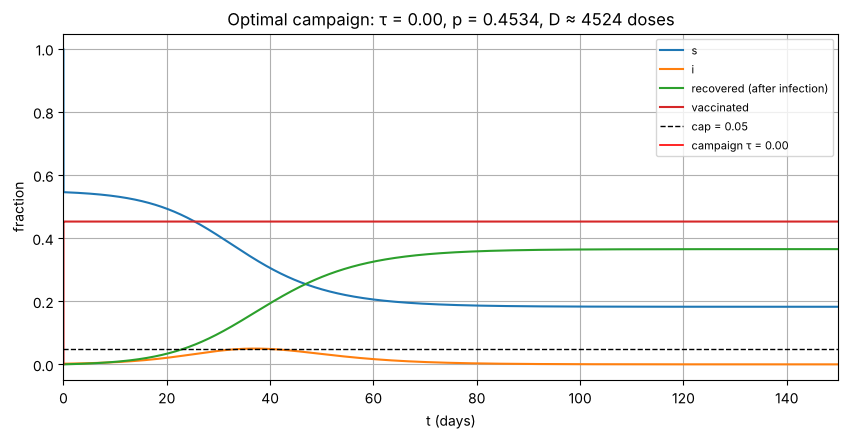

max |s+i+rec+v - 1| : 1.9984014443252818e-15
smallest value of any compartment: 0.0
max i * N : 499.99999999876775


In [17]:
tt, yy = simulate(tau=best.tau, p=best.p_min)
plt.figure(figsize=(10, 4.5))
plt.plot(tt, yy[:, 0], label="s"); plt.plot(tt, yy[:, 1], label="i")
plt.plot(tt, yy[:, 2], label="recovered (after infection)"); plt.plot(tt, yy[:, 3], label="vaccinated")
plt.axhline(cap, color="k", ls="--", lw=1, label="cap = 0.05")
plt.axvline(best.tau, color="r", lw=1.2, label=f"campaign τ = {best.tau:.2f}")
plt.xlim(0, 150); plt.xlabel("t (days)"); plt.ylabel("fraction"); plt.legend(fontsize=8)
plt.title(f"Optimal campaign: τ = {best.tau:.2f}, p = {best.p_min:.4f}, D ≈ {best['doses D']:.0f} doses")
plt.show()

total = yy.sum(axis=1)
print("max |s+i+rec+v - 1| :", np.abs(total - 1).max())
print("smallest value of any compartment:", yy.min())
print("max i * N :", yy[:, 1].max()*N)

In [18]:
# stability: halve dt and also use a finer search near the optimum
taus_fine2 = np.round(np.arange(0.0, 0.2 + 1e-9, 0.005), 3)
fine2 = min_p_table(taus_fine2, dt=dt3/2, n_bisect=50)
ff2 = fine2[fine2.feasible]
best2 = ff2.loc[ff2["doses D"].idxmin()]

# feasibility boundary with both step sizes
for h in [dt3, dt3/2]:
    tb, yb = simulate(dt=h, t_max=12)
    t_cross = tb[np.argmax(yb[:, 1] > cap)]
    print(f"dt = {h}: i first exceeds 0.05 at t = {t_cross:.3f} days")

print(pd.DataFrame({"dt=0.01, step 0.01": [best.tau, best.p_min, best['doses D']],
                    "dt=0.005, step 0.005": [best2.tau, best2.p_min, best2['doses D']]},
                   index=["tau*", "p*", "D*"]))

# feasibility decisions at tau = 0, 15 and coarse grid should not change
chk = min_p_table(taus, dt=dt3/2)
print("\nfeasibility decisions identical on coarse grid with dt/2:", (chk.feasible == res.feasible).all())
print("max change in p_min on coarse grid:", np.nanmax(np.abs(chk.p_min - res.p_min)))

dt = 0.01: i first exceeds 0.05 at t = 8.330 days
dt = 0.005: i first exceeds 0.05 at t = 8.325 days
      dt=0.01, step 0.01  dt=0.005, step 0.005
tau*             0.00000               0.00000
p*               0.45336               0.45336
D*            4524.48741            4524.48741



feasibility decisions identical on coarse grid with dt/2: True
max change in p_min on coarse grid: 1.3313638302925312e-08


**Checks:**
- s + i + rec + v stays equal to 1 up to round-off (~1e-15), and no compartment goes negative.
- The maximum of i in the optimal run is exactly 500 people (the constraint is active, as expected for a minimum p).
- With dt halved and a 0.005-day search grid the optimum is still τ = 0, and p* and D* only change in the far decimal places. The feasibility decision for every τ on the coarse grid is unchanged, and the boundary crossing time (≈ 8.33 days) is the same with both step sizes.

**Overall:** the cheapest feasible campaign is the earliest one, on day 0, with about 45% of susceptibles vaccinated (≈ 4524 doses). Waiting only makes it more expensive, and any campaign after about day 8.33 (including day 15) can't meet the requirement because the limit is already broken before the campaign starts.